# Практическая работа 5.2. Обучение модели


## Импорты


In [1]:
from __future__ import annotations

import os
import random
from pathlib import Path

PRACTICE_DIR = Path.cwd()
CACHE_DIR = PRACTICE_DIR / ".cache"
DATA_DIR = PRACTICE_DIR / ".data"
MPL_CACHE_DIR = CACHE_DIR / "matplotlib"
IPYTHON_CACHE_DIR = CACHE_DIR / "ipython"
XDG_CACHE_DIR = CACHE_DIR / "xdg"
MODEL_PATH = PRACTICE_DIR / "СП-М-О-КЗ-2025-Практика-5-2-БабушкинМВ.keras"

for directory in (CACHE_DIR, DATA_DIR, MPL_CACHE_DIR, IPYTHON_CACHE_DIR, XDG_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["MPLCONFIGDIR"] = str(MPL_CACHE_DIR)
os.environ["IPYTHONDIR"] = str(IPYTHON_CACHE_DIR)
os.environ["XDG_CACHE_HOME"] = str(XDG_CACHE_DIR)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from tensorflow.keras import Sequential, layers

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE = 8
EPOCHS = 10

PREPARED_DATASET_DIR = DATA_DIR / "wonders-of-world-prepared"
TRAIN_ROOT = PREPARED_DATASET_DIR / "train"
VALIDATION_ROOT = PREPARED_DATASET_DIR / "validation"
TEST_ROOT = PREPARED_DATASET_DIR / "test"

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")


## Описание данных

В работе используется подготовленный датасет `wonders-of-world-prepared`, созданный в notebook `5.1`. Он содержит `7` классов: `burj_khalifa`, `chichen_itza`, `christ_the_reedemer`, `eiffel_tower`, `machu_pichu`, `pyramids_of_giza`, `roman_colosseum`.


### Подготовленный датасет


In [3]:
def load_prepared_dataset_info(
    train_root: Path,
    validation_root: Path,
    test_root: Path,
) -> tuple[list[str], dict[str, dict[str, int]]]:
    """
    Считывает информацию о подготовленном датасете.

    Parameters
    ----------
    train_root : Path
        Каталог train.
    validation_root : Path
        Каталог validation.
    test_root : Path
        Каталог test.

    Returns
    -------
    tuple[list[str], dict[str, dict[str, int]]]
        Названия классов и количество изображений по выборкам.
    """
    if not all(root.is_dir() for root in (train_root, validation_root, test_root)):
        raise FileNotFoundError("Не найден prepared датасет. Сначала выполните notebook 5.1.")

    class_names = sorted(
        directory.name
        for directory in train_root.iterdir()
        if directory.is_dir()
    )

    split_counts: dict[str, dict[str, int]] = {}
    split_mapping = {
        "train": train_root,
        "validation": validation_root,
        "test": test_root,
    }

    for split_name, split_root in split_mapping.items():
        split_counts[split_name] = {}

        for class_name in class_names:
            class_root = split_root / class_name
            class_images = [
                image_path
                for image_path in class_root.iterdir()
                if image_path.is_file()
            ]
            split_counts[split_name][class_name] = len(class_images)

    return class_names, split_counts


In [4]:
class_names, split_counts = load_prepared_dataset_info(
    TRAIN_ROOT,
    VALIDATION_ROOT,
    TEST_ROOT,
)

print("Классы:", class_names)
for split_name, counts in split_counts.items():
    print(f"{split_name.capitalize()}: {sum(counts.values())}")
    for class_name, count in counts.items():
        print(f"  {class_name}: {count}")


Классы: ['burj_khalifa', 'christ_the_redeemer', 'eiffel_tower', 'machu_picchu', 'pyramids_of_giza', 'roman_colosseum', 'statue_of_liberty']
Train: 1176
  burj_khalifa: 168
  christ_the_redeemer: 168
  eiffel_tower: 168
  machu_picchu: 168
  pyramids_of_giza: 168
  roman_colosseum: 168
  statue_of_liberty: 168
Validation: 245
  burj_khalifa: 35
  christ_the_redeemer: 35
  eiffel_tower: 35
  machu_picchu: 35
  pyramids_of_giza: 35
  roman_colosseum: 35
  statue_of_liberty: 35
Test: 245
  burj_khalifa: 35
  christ_the_redeemer: 35
  eiffel_tower: 35
  machu_picchu: 35
  pyramids_of_giza: 35
  roman_colosseum: 35
  statue_of_liberty: 35


## Загрузка данных через TensorFlow

Изображения считываются из готовых папок `train`, `validation` и `test`.


In [5]:
def make_tf_dataset(
    split_root: Path,
    class_names: list[str],
    *,
    shuffle: bool,
) -> tf.data.Dataset:
    """
    Создает TensorFlow Dataset из директории выборки.

    Parameters
    ----------
    split_root : Path
        Каталог train, validation или test.
    class_names : list[str]
        Названия классов.
    shuffle : bool
        Нужно ли перемешивать выборку.

    Returns
    -------
    tf.data.Dataset
        Датасет изображений и меток.
    """
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory=str(split_root),
        labels="inferred",
        label_mode="int",
        class_names=class_names,
        image_size=(IMAGE_SIZE, IMAGE_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )
    return dataset.prefetch(tf.data.AUTOTUNE)


In [6]:
train_dataset = make_tf_dataset(
    TRAIN_ROOT,
    class_names,
    shuffle=True,
)
validation_dataset = make_tf_dataset(
    VALIDATION_ROOT,
    class_names,
    shuffle=False,
)
test_dataset = make_tf_dataset(
    TEST_ROOT,
    class_names,
    shuffle=False,
)


Found 1176 files belonging to 7 classes.
Found 245 files belonging to 7 classes.
Found 245 files belonging to 7 classes.


I0000 00:00:1778082505.320904 33784732 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1778082505.320933 33784732 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## Превью данных


In [7]:
def show_dataset_preview(
    dataset: tf.data.Dataset,
    class_names: list[str],
    *,
    num_images: int = 12,
) -> None:
    """
    Показывает несколько изображений из TensorFlow Dataset.

    Parameters
    ----------
    dataset : tf.data.Dataset
        Датасет изображений и меток.
    class_names : list[str]
        Названия классов.
    num_images : int
        Количество изображений в превью.
    """
    images, labels = next(iter(dataset))
    preview_size = min(num_images, images.shape[0])

    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    axes = np.asarray(axes).reshape(-1)

    for axis, image, label in zip(axes, images[:preview_size], labels[:preview_size]):
        axis.imshow(image.numpy().astype("uint8"))
        axis.set_title(class_names[int(label)], fontsize=9)
        axis.axis("off")

    for axis in axes[preview_size:]:
        axis.axis("off")

    plt.tight_layout()
    plt.show()


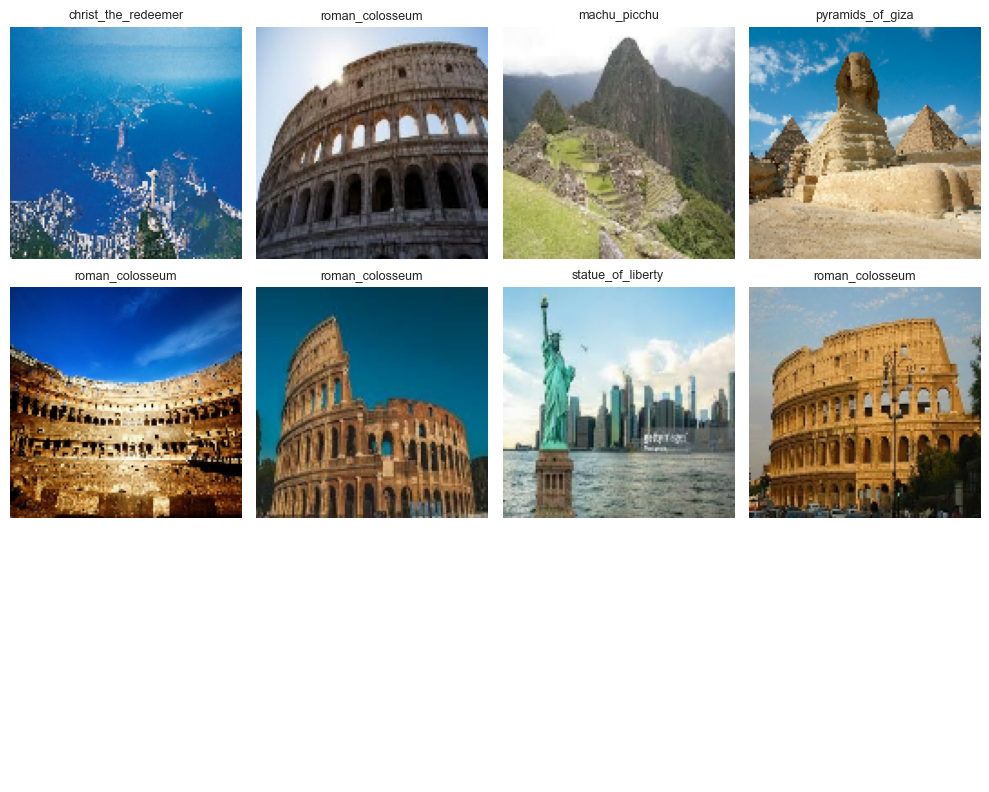

In [8]:
show_dataset_preview(
    train_dataset,
    class_names,
)


## Модель

За основу берется простая сверточная сеть без сложной дополнительной обвязки. В первых трех блоках число фильтров растет от `32` до `128`, затем выполняется `Flatten`, полносвязный слой на `256` нейронов и выход `softmax`.


In [9]:
model = Sequential(
    [
        # Rescaling нормализует изображение: переводит значения пикселей
        # из диапазона 0..255 в диапазон 0..1.
        layers.Rescaling(1.0 / 255, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
        # Conv2D — сверточный слой.
        # 32 фильтра размера 3x3 ищут простые признаки: границы, контуры,
        # перепады яркости и цвета.
        # padding="same" сохраняет размер карты признаков.
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        # MaxPooling2D уменьшает размер карты признаков
        # и оставляет наиболее сильные отклики.
        layers.MaxPooling2D(),
        # Второй сверточный слой работает уже с найденными признаками
        # и собирает из них более сложные детали объекта.
        # Число фильтров увеличено до 64.
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        # Повторный pooling снова уменьшает размер представления.
        layers.MaxPooling2D(),
        # Третий сверточный слой выделяет более сложные сочетания признаков.
        # Число фильтров увеличено до 128.
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        # Еще один pooling перед переходом к полносвязной части.
        layers.MaxPooling2D(),
        # Flatten превращает многомерную карту признаков в один вектор.
        layers.Flatten(),
        # Dense — полносвязный скрытый слой.
        # Здесь он объединяет все найденные признаки перед классификацией.
        # Размер 256 выбран как емкость скрытого слоя.
        layers.Dense(256, activation="relu"),
        # Dropout отключает часть нейронов во время обучения
        # и помогает уменьшить переобучение.
        layers.Dropout(0.50),
        # Выходной слой содержит 7 нейронов по числу классов.
        # Функция softmax переводит выход сети в вероятности классов.
        layers.Dense(len(class_names), activation="softmax"),
    ]
)


/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Проверка структуры модели


In [10]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,911 (32.36 MB)

 Trainable params: 8,483,911 (32.36 MB)

 Non-trainable params: 0 (0.00 B)

## Обучение модели

Модель обучается на `train`, проверяется на `validation`, а затем оценивается на `test`.


In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)


In [12]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
)


Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.3342 - loss: 1.7085 - val_accuracy: 0.5184 - val_loss: 1.3430
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4949 - loss: 1.3248 - val_accuracy: 0.6490 - val_loss: 1.0485
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6241 - loss: 1.0822 - val_accuracy: 0.6449 - val_loss: 0.9880
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.6820 - loss: 0.8966 - val_accuracy: 0.7388 - val_loss: 0.8194
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7364 - loss: 0.7854 - val_accuracy: 0.7551 - val_loss: 0.7774
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7857 - loss: 0.6103 - val_accuracy: 0.7347 - val_loss: 0.8907
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8316 - loss: 0.4832 - val_accuracy: 0.7592 - val_loss: 0.7761
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8622 - loss: 0.4222 - val_accu

## Графики


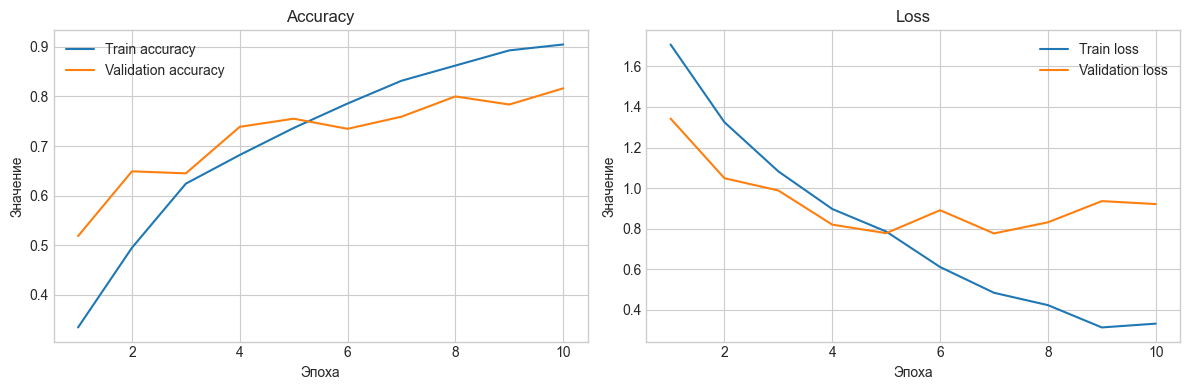

In [13]:
history_dict = history.history
epochs_range = range(1, len(history_dict["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history_dict["accuracy"], label="Train accuracy")
axes[0].plot(epochs_range, history_dict["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Значение")
axes[0].legend()

axes[1].plot(epochs_range, history_dict["loss"], label="Train loss")
axes[1].plot(epochs_range, history_dict["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Значение")
axes[1].legend()

plt.tight_layout()
plt.show()


## Оценка качества


In [14]:
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


Test loss: 0.7945
Test accuracy: 0.8000


In [15]:
probabilities = model.predict(test_dataset, verbose=0)
predicted_labels = probabilities.argmax(axis=1)
true_labels = np.concatenate([labels.numpy() for _, labels in test_dataset], axis=0)


## Матрица ошибок


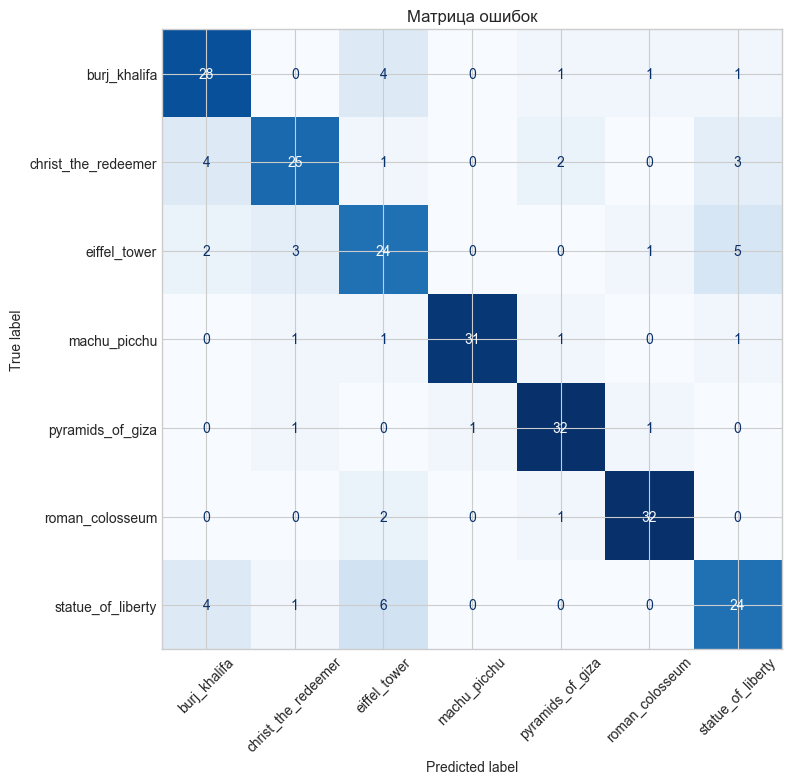

In [16]:
confusion = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=np.arange(len(class_names)),
)

fig, axis = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=class_names,
).plot(
    ax=axis,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
)
axis.set_title("Матрица ошибок")
plt.tight_layout()
plt.show()


## Сохранение модели


In [17]:
model.save(MODEL_PATH)
print(f"Модель сохранена: {MODEL_PATH}")


Модель сохранена: /Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 5 - Основы работы в Keras/СП-М-О-КЗ-2025-Практика-5-2-БабушкинМВ.keras
